# 02 — Exploratory Data Analysis (EDA)

## Objective
Explore relationships between machine operating conditions and failure.

### Main analyses
- Target distribution
- Numerical distributions
- Machine type vs failure
- Correlation matrix
- Sensor variables vs failure
- Outlier inspection

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset.csv"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
numeric_cols = df.select_dtypes(include=np.number).columns.drop("Failure").tolist()

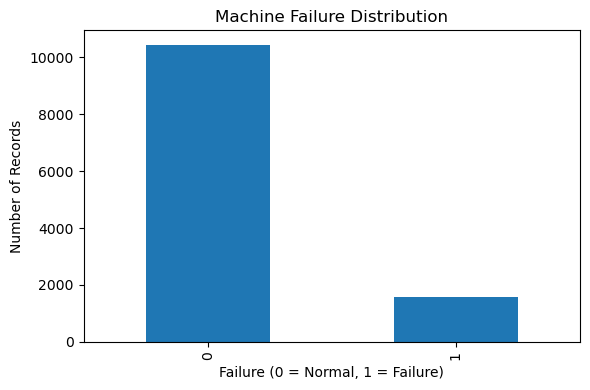

In [2]:
# 1. Target distribution
plt.figure(figsize=(6, 4))
df["Failure"].value_counts().sort_index().plot(kind="bar")
plt.title("Machine Failure Distribution")
plt.xlabel("Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()

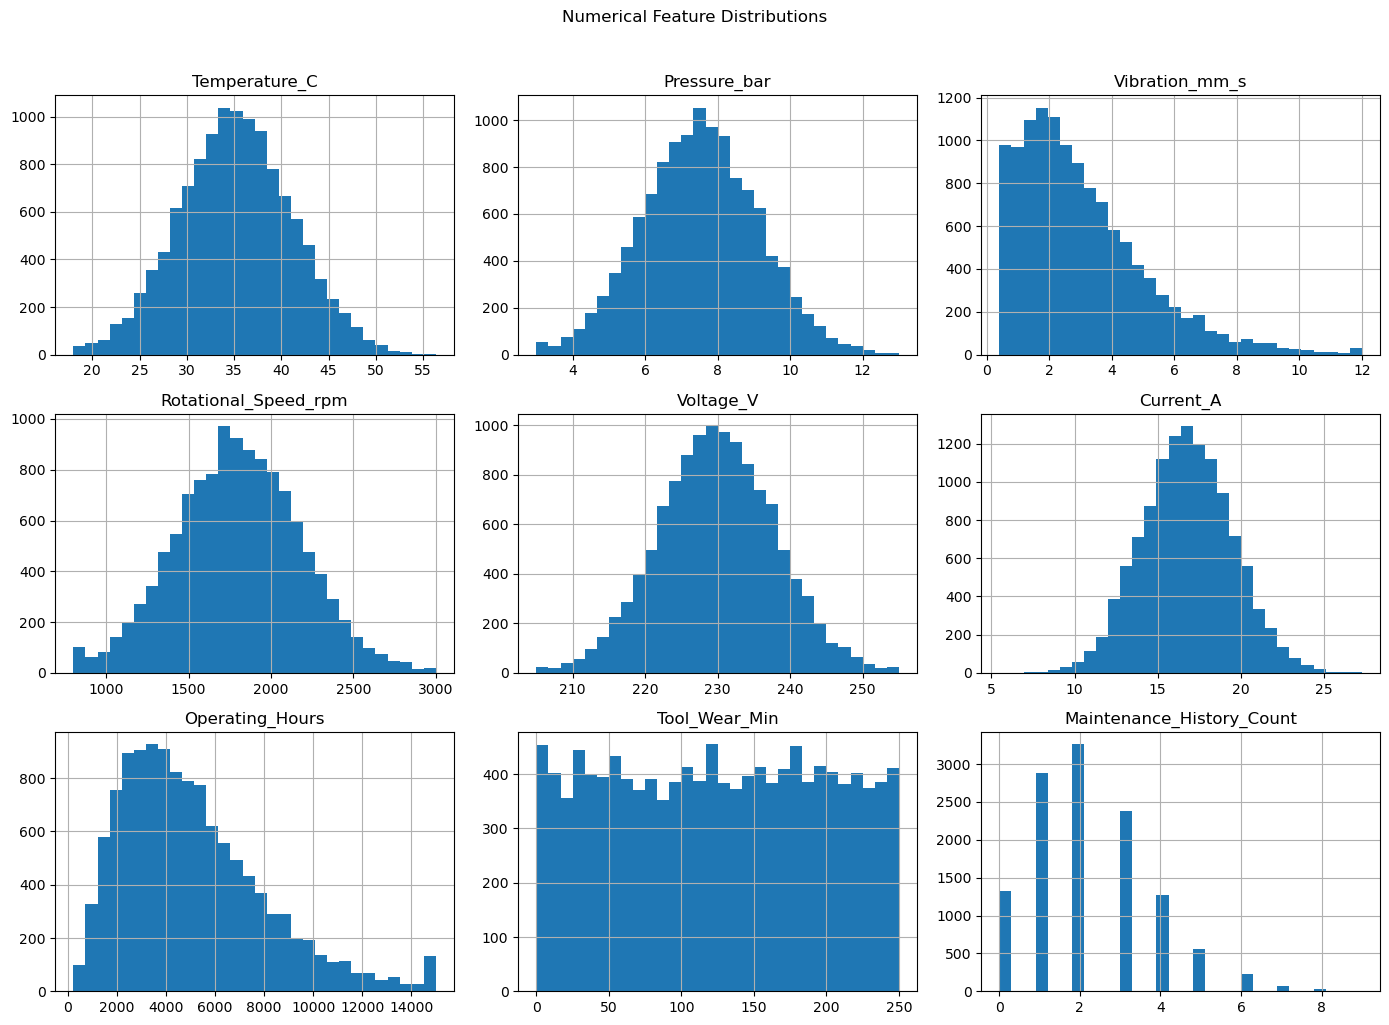

In [3]:
# 2. Numerical distributions
df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Numerical Feature Distributions", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

,count,Failures,Failure_Rate
Machine_Type,,,
H,2346,333,14.194373
L,6010,758,12.612313
M,3644,476,13.062569


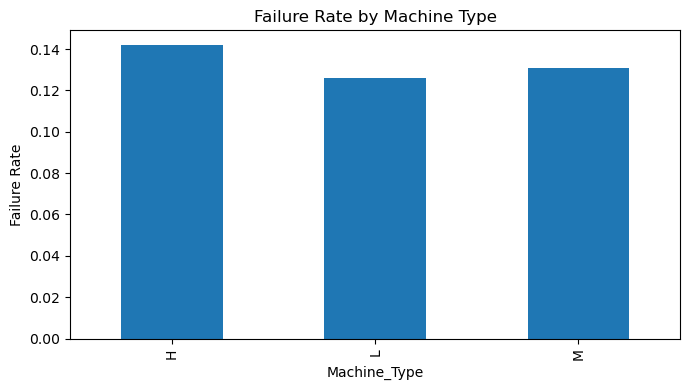

In [4]:
# 3. Failure rate by machine type
failure_by_type = (
    df.groupby("Machine_Type")["Failure"]
      .agg(["count", "sum", "mean"])
      .rename(columns={"sum": "Failures", "mean": "Failure_Rate"})
)
failure_by_type["Failure_Rate"] *= 100
display(failure_by_type)

plt.figure(figsize=(7, 4))
df.groupby("Machine_Type")["Failure"].mean().plot(kind="bar")
plt.title("Failure Rate by Machine Type")
plt.ylabel("Failure Rate")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_failure_by_machine_type.png", dpi=150)
plt.show()

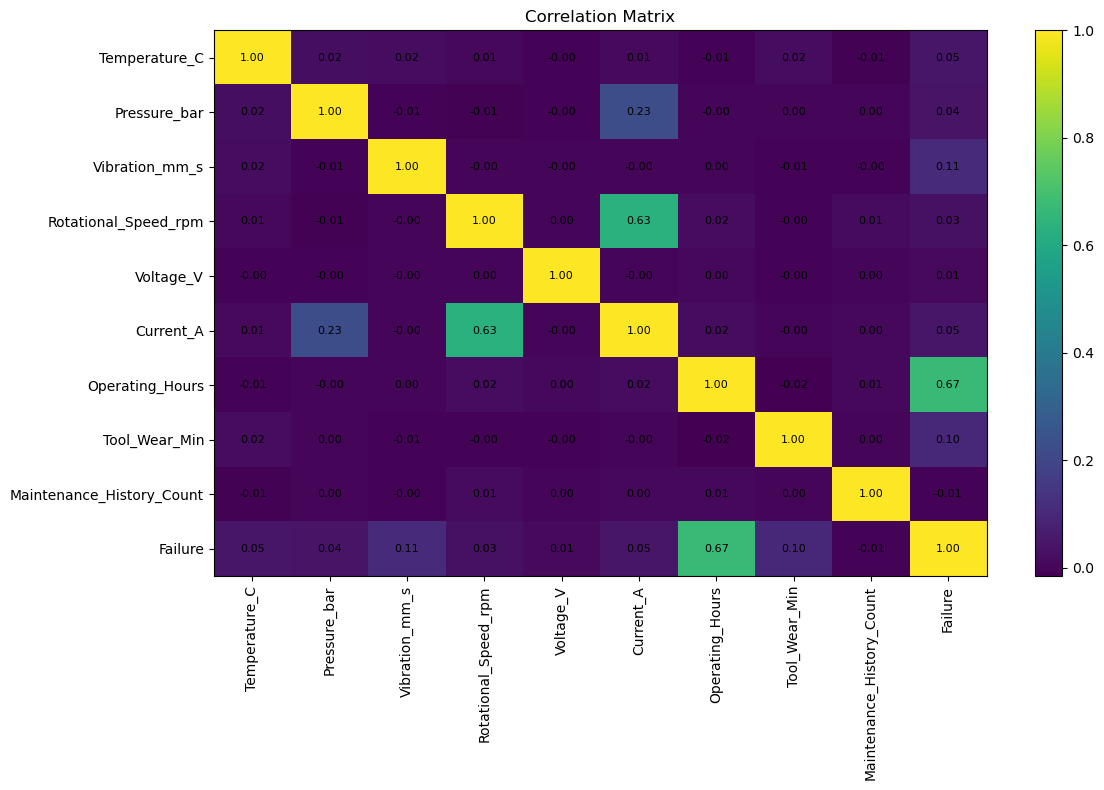

In [5]:
# 4. Correlation matrix for numerical variables
corr = df[numeric_cols + ["Failure"]].corr()

plt.figure(figsize=(12, 8))
plt.imshow(corr, aspect="auto", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_correlation_matrix.png", dpi=150)
plt.show()

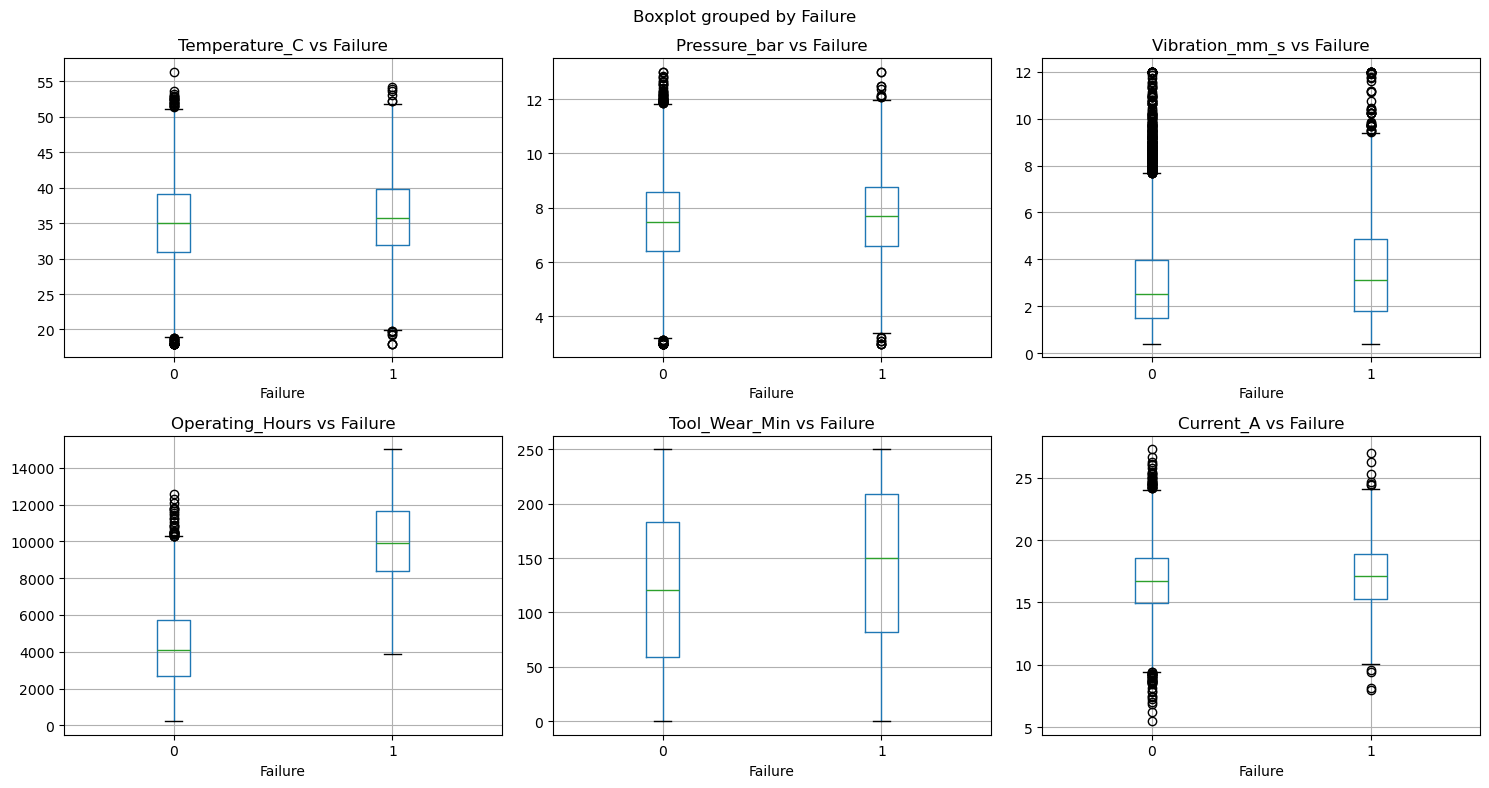

In [6]:
# 5. Compare important operating variables by target
selected = ["Temperature_C", "Pressure_bar", "Vibration_mm_s",
            "Operating_Hours", "Tool_Wear_Min", "Current_A"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), selected):
    df.boxplot(column=col, by="Failure", ax=ax)
    ax.set_title(f"{col} vs Failure")
    ax.set_xlabel("Failure")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_features_vs_failure.png", dpi=150)
plt.show()

In [7]:
# 6. Outlier counts using the IQR rule
outlier_rows = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append([col, lower, upper, count])

outlier_summary = pd.DataFrame(
    outlier_rows,
    columns=["Feature", "Lower_Bound", "Upper_Bound", "Outlier_Count"]
)
display(outlier_summary.sort_values("Outlier_Count", ascending=False))

,Feature,Lower_Bound,Upper_Bound,Outlier_Count
2,Vibration_mm_s,-2.28500,7.91500,364
6,Operating_Hours,-2758.00000,12322.00000,303
8,Maintenance_History_Count,-2.00000,6.00000,100
1,Pressure_bar,3.16500,11.84500,90
4,Voltage_V,208.22000,251.74000,82
5,Current_A,9.49875,24.10875,82
0,Temperature_C,18.98500,51.26500,66
3,Rotational_Speed_rpm,768.87500,2829.87500,43
7,Tool_Wear_Min,-128.00000,376.00000,0



## Key Findings

Complete this section after running the notebook.

### 1. Target Distribution
Describe the number and percentage of normal and failure records.

### 2. Feature Distributions
Describe the observed ranges and distributions of sensor features.

### 3. Machine Type Analysis
Compare the observed failure rates across machine types.

### 4. Correlation Analysis
Discuss notable correlations. Remember that correlation does not
establish causation.

### 5. Outlier Analysis
Explain which variables contain potential outliers and why they
should not automatically be removed.

### Conclusion
Summarize how the EDA findings influenced the preprocessing
and model evaluation stages.
